<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Pr%C3%A9traitement_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Checkpoint: Prétraitement

**Objectif**

Appliquer des techniques de nettoyage des données et de mise à l'échelle des caractéristiques afin de préparer un ensemble de données pour l'apprentissage automatique.

In [1]:
#Importer le jeu de données
from sklearn.datasets import load_wine
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Iris dataset
wine_data = load_wine()

# Create a DataFrame from the data and feature names
wine = pd.DataFrame(data=wine_data.data, columns=wine_data.feature_names)


In [3]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

In [8]:
wine.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [13]:
print("Valeurs manquantes :", wine.isnull().sum().sum())
print("Doublons :", wine.duplicated().sum())

Valeurs manquantes : 0
Doublons : 0


In [14]:
X = wine_data.data
y = wine_data.target

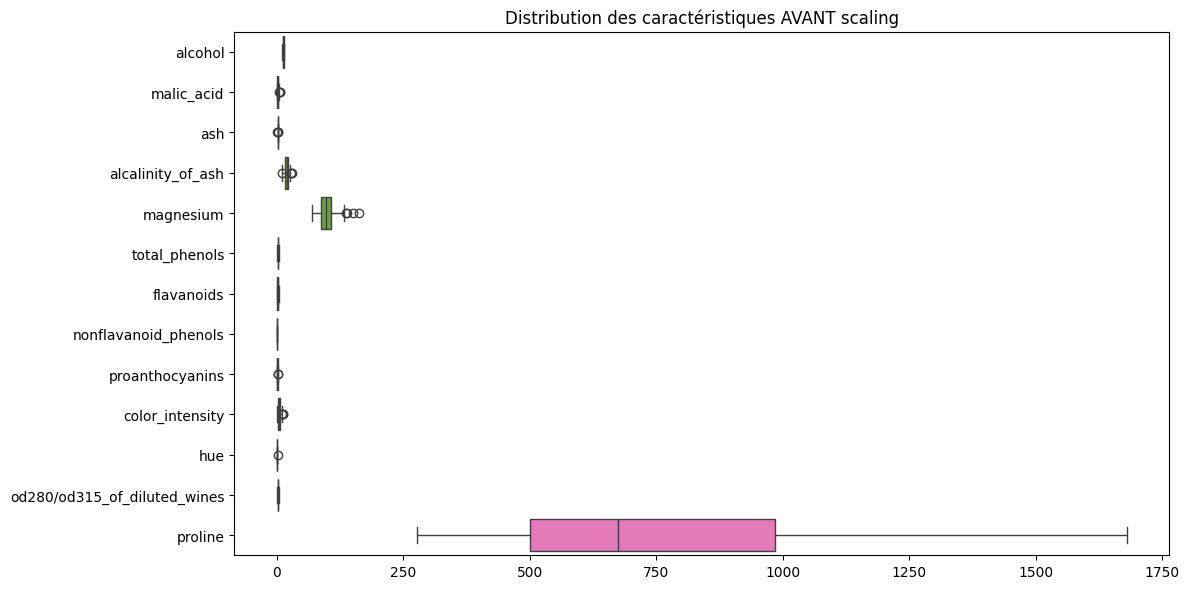

In [12]:
# ------------------------------------------------------------
# 2. Visualisation des échelles (avant scaling)
# ------------------------------------------------------------
plt.figure(figsize=(12, 6))
sns.boxplot(data=X, orient="h")
plt.title("Distribution des caractéristiques AVANT scaling")
plt.tight_layout()
plt.show()

In [15]:
# Diviser les données
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain : {X_train.shape[0]} échantillons")
print(f"Test  : {X_test.shape[0]} échantillons")



Train : 142 échantillons
Test  : 36 échantillons


In [23]:
# Mise à l'échelle des caractéristiques
from sklearn.preprocessing import StandardScaler

# --- StandardScaler (moyenne = 0, écart-type = 1) ---
scaler_std = StandardScaler()
X_train_std = scaler_std.fit_transform(X_train)
X_test_std  = scaler_std.transform(X_test)



# Convertir en DataFrame pour visualisation (correction : utilisation de wine.columns)
X_train_std_df = pd.DataFrame(X_train_std, columns=wine.columns)


X_train_std_df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.385801,-0.637871,1.776668,-1.224532,0.696430,0.526865,0.732292,-0.169549,-0.415783,-0.167467,0.624378,0.252908,0.467725
1,0.948519,-0.765445,1.253174,0.853284,0.091785,1.172795,1.333181,-0.590457,1.349742,0.305303,1.067155,0.151048,1.815768
2,0.523354,-0.519409,0.954034,-1.046433,-0.445678,0.930572,1.006382,-0.169549,-0.260002,-0.081509,-0.128343,0.893172,1.516203
3,0.973529,-0.555859,0.168793,-1.076116,-0.714409,0.526865,0.816627,-0.590457,0.363125,0.262324,0.890044,0.427526,1.932265
4,0.435820,0.820120,0.056615,0.556453,-0.512860,-0.555068,-1.291756,0.756449,-0.606183,1.474335,-1.766619,-1.435059,-0.297831
...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,0.685917,0.756333,1.327959,1.150115,-0.176946,-1.168702,-1.544762,1.177357,-1.817818,-0.274915,-0.261176,-0.794796,-0.730536
138,-1.652489,-0.610534,0.954034,1.892192,-0.781592,-0.571216,-0.395693,0.335541,-0.450402,-1.027050,1.819877,0.878620,-0.590739
139,0.673412,-0.492072,1.066212,-0.185624,0.696430,0.123159,0.574163,-0.590457,-0.104220,-0.339384,0.668656,0.383871,1.183353
140,-0.014354,1.011481,-0.055562,-0.334039,0.427699,-1.427074,-1.355008,0.335541,-1.142765,0.124791,-1.191008,-1.245891,-0.214618


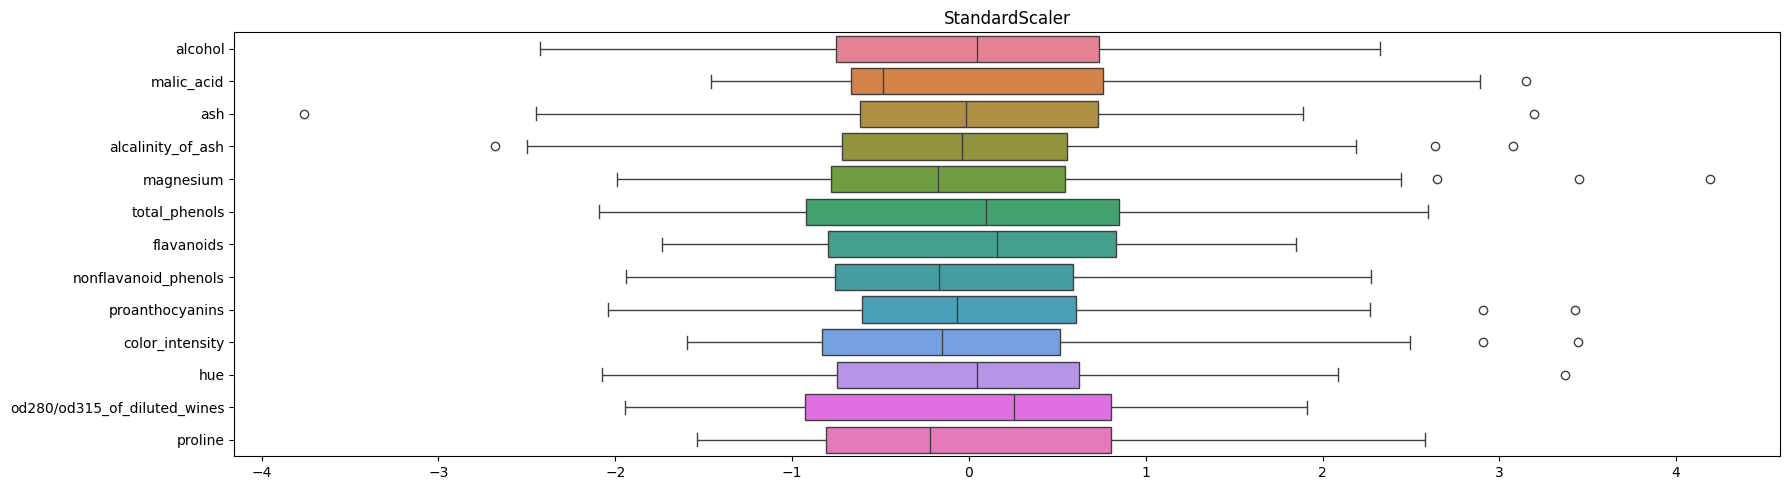

In [25]:
# ------------------------------------------------------------
# 5. Visualisation après scaling
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 1, figsize=(18, 5))

sns.boxplot(data=X_train_std_df, orient="h", ax=axes)
axes.set_title("StandardScaler")

plt.tight_layout()
plt.show()

# Documentez votre processus
- Aucun problème de netoyage des données identifié
- La méthode de mise à l'échelle est la Standardisation (StandardScaler) par ce que les caractéristiques du dataset ont des échelles très différentes.
StandardScaler ramène toutes les features à la même échelle (moyenne 0, écart-type 1)
